In [41]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_curve, auc, roc_auc_score
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [42]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"

columns = [
    'Sepal.Length',
    'Sepal.Width',
    'Petal.Length',
    'Petal.Width',
    'Species'
]

iris = pd.read_csv(url, names=columns).dropna()

print("Dataset loaded successfully!")
print("Dataset Shape:", iris.shape)
display(iris.head())

Dataset loaded successfully!
Dataset Shape: (150, 5)


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Sepal.Length  150 non-null    float64
 1   Sepal.Width   150 non-null    float64
 2   Petal.Length  150 non-null    float64
 3   Petal.Width   150 non-null    float64
 4   Species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Statistical Summary:


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



Missing Values:
Sepal.Length    0
Sepal.Width     0
Petal.Length    0
Petal.Width     0
Species         0
dtype: int64

Duplicate Records: 3


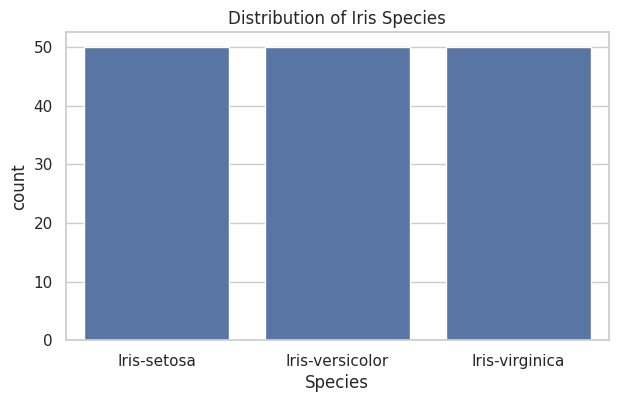

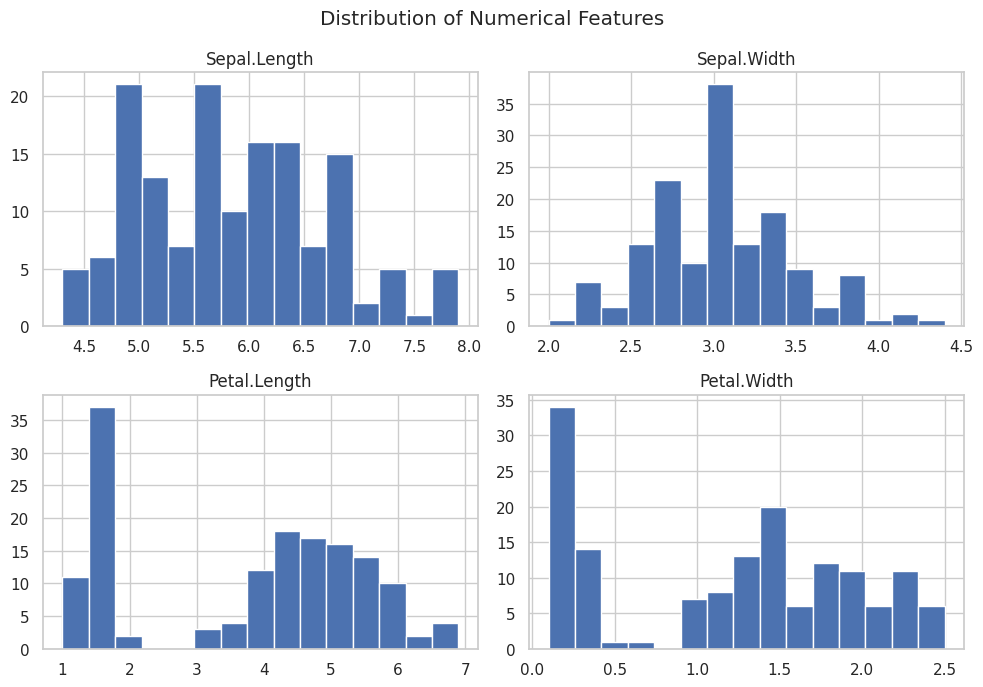

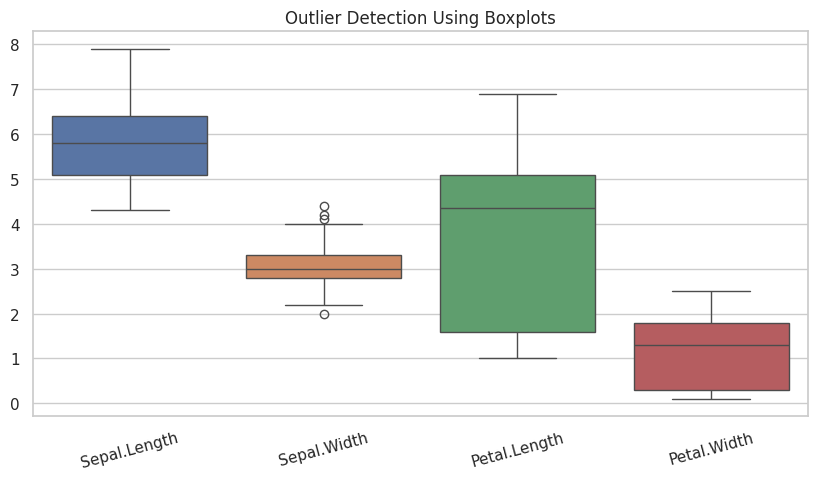

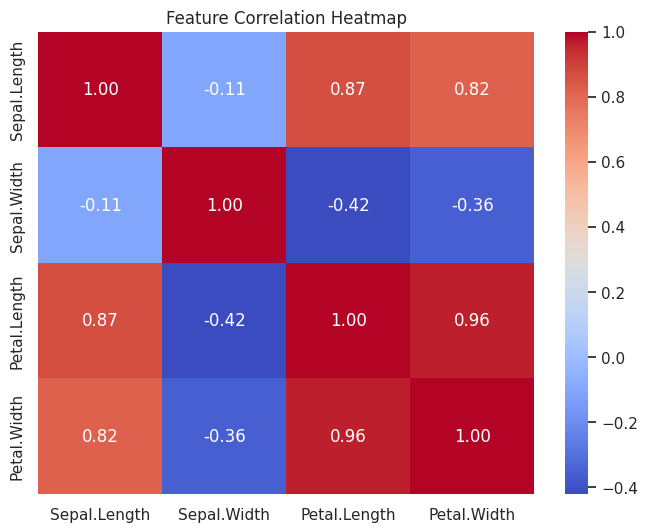

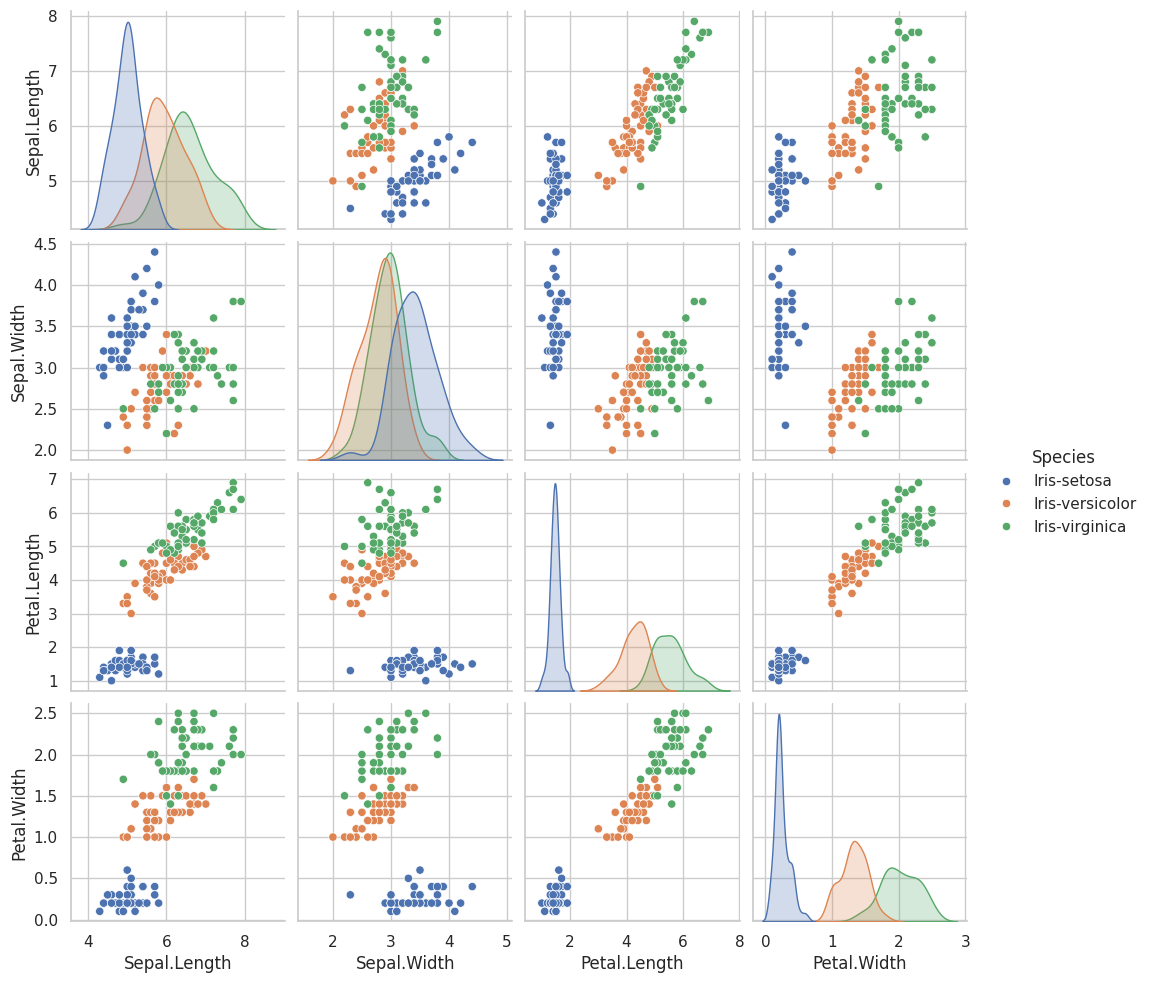

In [43]:

# EXPLORATORY DATA ANALYSIS

# 1. Dataset information
print("Dataset Information:")
iris.info()

# 2. Statistical summary
print("\nStatistical Summary:")
display(iris.describe())

# 3. Missing values
print("\nMissing Values:")
print(iris.isnull().sum())

# 4. Duplicate records
print("\nDuplicate Records:", iris.duplicated().sum())

# 5. Species distribution
plt.figure(figsize=(7,4))
sns.countplot(data=iris, x='Species')
plt.title("Distribution of Iris Species")
plt.show()

# 6. Feature distributions
iris.iloc[:, :4].hist(figsize=(10,7), bins=15)
plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

# 7. Outlier detection
plt.figure(figsize=(10,5))
sns.boxplot(data=iris.iloc[:, :4])
plt.title("Outlier Detection Using Boxplots")
plt.xticks(rotation=15)
plt.show()

# 8. Correlation analysis
plt.figure(figsize=(8,6))
sns.heatmap(
    iris.iloc[:, :4].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title("Feature Correlation Heatmap")
plt.show()

# 9. Pairplot
sns.pairplot(iris, hue='Species')
plt.show()


In [44]:

# DATA PREPROCESSING

# 1. Inspect duplicate records
print("Duplicate records:")
display(iris[iris.duplicated(keep=False)])

# 2. Remove duplicate records
iris = iris.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", iris.shape)

# 3. Separate features and target
X = iris.drop('Species', axis=1)
y = iris['Species']

# 4. Encode target labels
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(y)

print("\nTarget Classes:")
print(le.classes_)

# 5. Split dataset into 70% training and 30% testing
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nPreprocessing completed successfully!")


Duplicate records:


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
9,4.9,3.1,1.5,0.1,Iris-setosa
34,4.9,3.1,1.5,0.1,Iris-setosa
37,4.9,3.1,1.5,0.1,Iris-setosa
101,5.8,2.7,5.1,1.9,Iris-virginica
142,5.8,2.7,5.1,1.9,Iris-virginica


Shape after removing duplicates: (147, 5)

Target Classes:
['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']

Training Data: (102, 4)
Testing Data: (45, 4)

Preprocessing completed successfully!


In [45]:

# MODEL TRAINING AND EVALUATION

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix,
    classification_report
)

# Define all five models
models = {
    "Logistic Regression": Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=1000))
    ]),

    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "KNN": Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors=5))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

# Train and evaluate models
results = []
trained_models = {}
predictions = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    trained_models[name] = model
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average='weighted', zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average='weighted', zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, average='weighted', zero_division=0
        )
    })

# Display comparison
results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
display(results_df.round(4))

# Classification reports
for name, y_pred in predictions.items():
    print("\n", "="*50)
    print(name)
    print(classification_report(
        y_test, y_pred, target_names=le.classes_
    ))


MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9111,0.9155,0.9111,0.9107
1,Decision Tree,0.8889,0.8899,0.8889,0.8888
2,KNN,0.9111,0.9298,0.9111,0.9095
3,Random Forest,0.9111,0.9155,0.9111,0.9107
4,Gradient Boosting,0.9333,0.9345,0.9333,0.9333



Logistic Regression
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       0.82      0.93      0.88        15
 Iris-virginica       0.92      0.80      0.86        15

       accuracy                           0.91        45
      macro avg       0.92      0.91      0.91        45
   weighted avg       0.92      0.91      0.91        45


Decision Tree
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       0.81      0.87      0.84        15
 Iris-virginica       0.86      0.80      0.83        15

       accuracy                           0.89        45
      macro avg       0.89      0.89      0.89        45
   weighted avg       0.89      0.89      0.89        45


KNN
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       0.79      1.00    

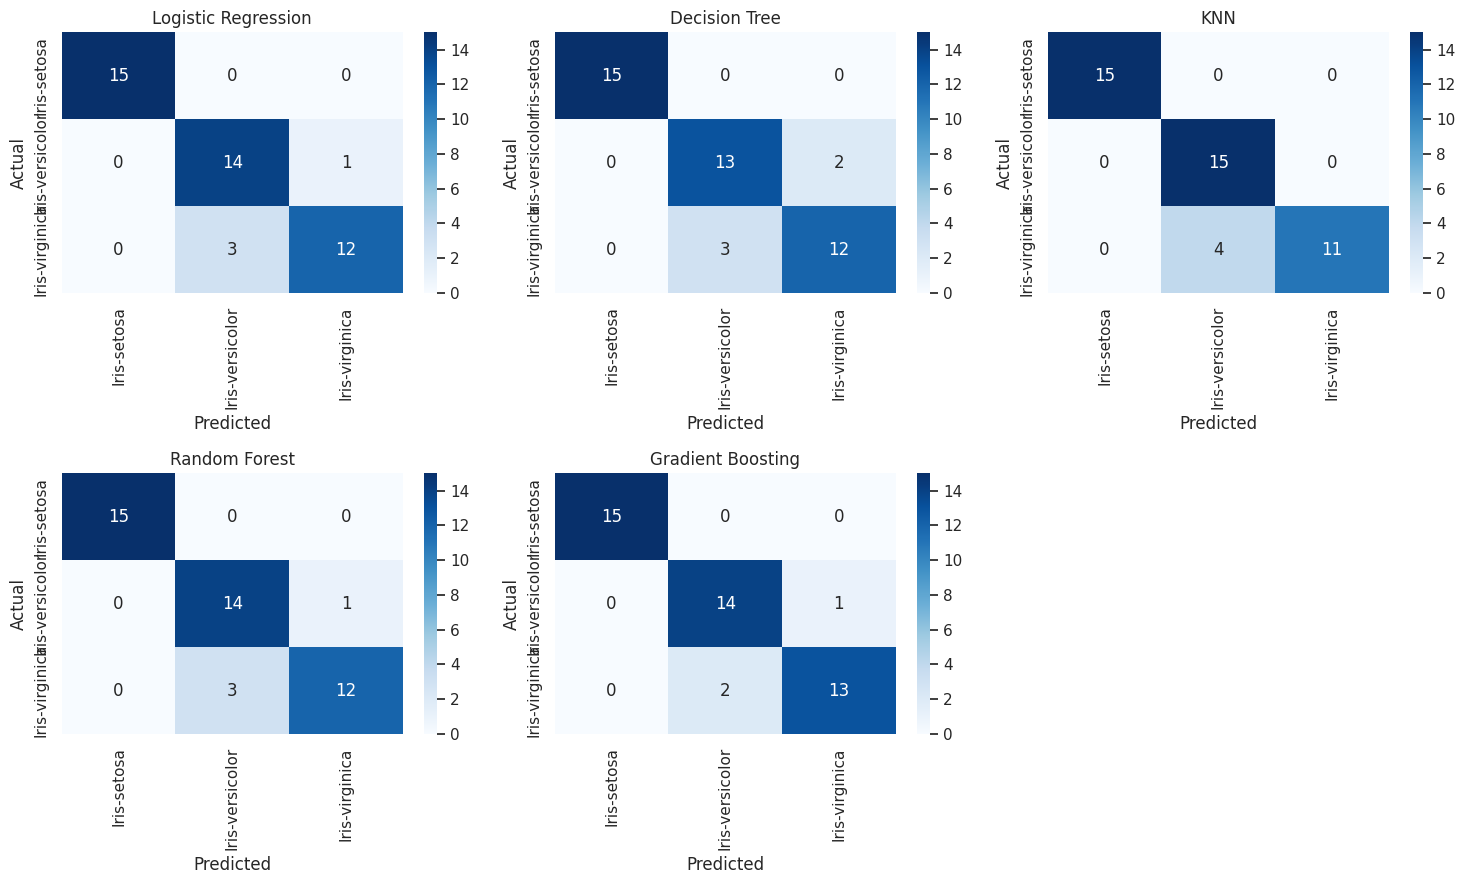

In [46]:

# CONFUSION MATRIX FOR ALL MODELS

from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=le.classes_,
        yticklabels=le.classes_,
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

axes[5].axis('off')
plt.tight_layout()
plt.show()


In [47]:

# HYPERPARAMETER TUNING

from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Random Forest tuning
rf_params = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 3, 5, 10],
    'min_samples_split': [2, 5]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_params,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

# Gradient Boosting tuning
gb_params = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [2, 3, 4]
}

gb_grid = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    gb_params,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

gb_grid.fit(X_train, y_train)

print("Random Forest Best Parameters:")
print(rf_grid.best_params_)
print("Random Forest Best CV Accuracy:", rf_grid.best_score_)

print("\nGradient Boosting Best Parameters:")
print(gb_grid.best_params_)
print("Gradient Boosting Best CV Accuracy:", gb_grid.best_score_)


Random Forest Best Parameters:
{'max_depth': None, 'min_samples_split': 5, 'n_estimators': 50}
Random Forest Best CV Accuracy: 0.96

Gradient Boosting Best Parameters:
{'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 50}
Gradient Boosting Best CV Accuracy: 0.9604761904761905


In [48]:

# EVALUATION AFTER HYPERPARAMETER TUNING

best_models = {
    "Tuned Random Forest": rf_grid.best_estimator_,
    "Tuned Gradient Boosting": gb_grid.best_estimator_
}

tuned_results = []

for name, model in best_models.items():
    y_pred = model.predict(X_test)

    tuned_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average='weighted'),
        "Recall": recall_score(y_test, y_pred, average='weighted'),
        "F1 Score": f1_score(y_test, y_pred, average='weighted')
    })

tuned_df = pd.DataFrame(tuned_results)

print("TUNED MODEL PERFORMANCE")
display(tuned_df.round(4))


TUNED MODEL PERFORMANCE


,Model,Accuracy,Precision,Recall,F1 Score
0,Tuned Random Forest,0.9111,0.9155,0.9111,0.9107
1,Tuned Gradient Boosting,0.9333,0.9345,0.9333,0.9333


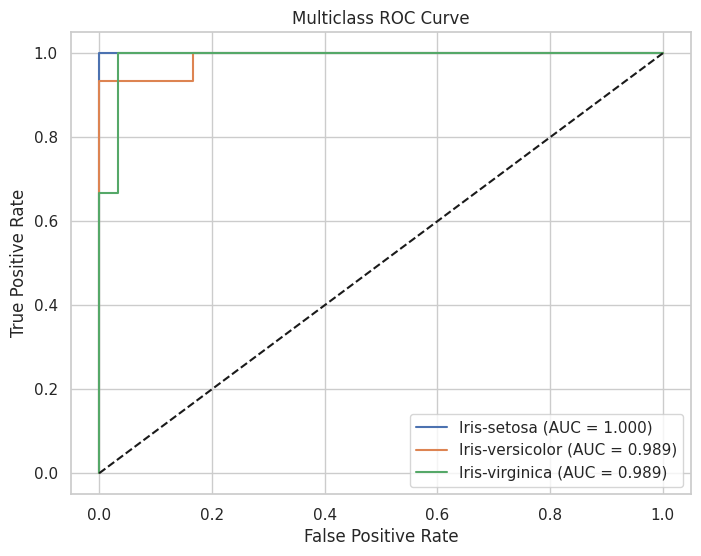

Macro Average ROC-AUC: 0.9926


In [49]:

# MULTICLASS ROC CURVE AND AUC

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# Use tuned Gradient Boosting
final_model = gb_grid.best_estimator_

y_score = final_model.predict_proba(X_test)

y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

plt.figure(figsize=(8, 6))

for i, class_name in enumerate(le.classes_):
    fpr, tpr, thresholds = roc_curve(
        y_test_bin[:, i], y_score[:, i]
    )

    class_auc = auc(fpr, tpr)

    plt.plot(
        fpr, tpr,
        label=f'{class_name} (AUC = {class_auc:.3f})'
    )

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multiclass ROC Curve')
plt.legend()
plt.show()

macro_auc = roc_auc_score(
    y_test_bin, y_score,
    average='macro',
    multi_class='ovr'
)

print("Macro Average ROC-AUC:", round(macro_auc, 4))


,Feature,Importance
3,Petal.Width,0.652498
2,Petal.Length,0.267702
1,Sepal.Width,0.078644
0,Sepal.Length,0.001156


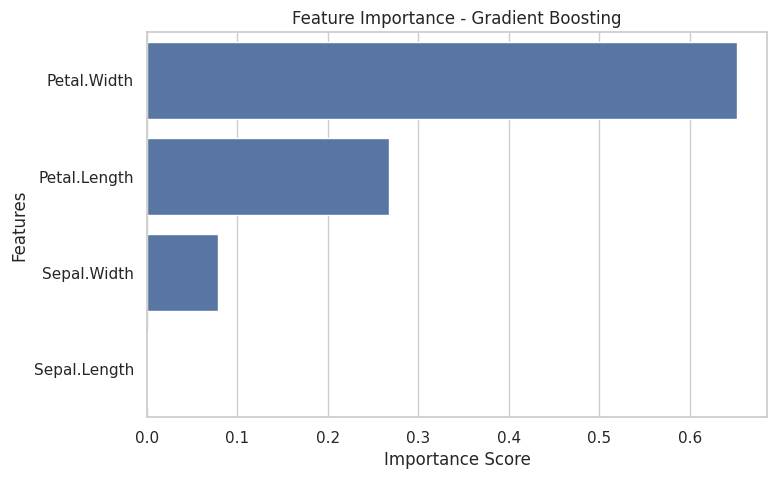

In [50]:
# FEATURE IMPORTANCE

final_model = gb_grid.best_estimator_

importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': final_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance', ascending=False
)

display(importance)

plt.figure(figsize=(8, 5))
sns.barplot(data=importance, x='Importance', y='Feature')
plt.title('Feature Importance - Gradient Boosting')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

In [51]:
# FINAL MODEL SELECTION

final_results = pd.concat(
    [results_df, tuned_df],
    ignore_index=True
)

display(
    final_results.sort_values(
        by='Accuracy', ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score
4,Gradient Boosting,0.9333,0.9345,0.9333,0.9333
6,Tuned Gradient Boosting,0.9333,0.9345,0.9333,0.9333
0,Logistic Regression,0.9111,0.9155,0.9111,0.9107
3,Random Forest,0.9111,0.9155,0.9111,0.9107
2,KNN,0.9111,0.9298,0.9111,0.9095
5,Tuned Random Forest,0.9111,0.9155,0.9111,0.9107
1,Decision Tree,0.8889,0.8899,0.8889,0.8888


In [52]:
# FINAL MODEL SELECTION SUMMARY

all_results = pd.concat(
    [results_df, tuned_df],
    ignore_index=True
)

best_model_row = all_results.loc[
    all_results['Accuracy'].idxmax()
]

print("BEST PERFORMING MODEL")
print("---------------------")
print("Model:", best_model_row['Model'])
print("Accuracy:", round(best_model_row['Accuracy'], 4))
print("Precision:", round(best_model_row['Precision'], 4))
print("Recall:", round(best_model_row['Recall'], 4))
print("F1 Score:", round(best_model_row['F1 Score'], 4))

BEST PERFORMING MODEL
---------------------
Model: Gradient Boosting
Accuracy: 0.9333
Precision: 0.9345
Recall: 0.9333
F1 Score: 0.9333
